In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis
from typing import Dict, Tuple
import os
import seaborn as sns

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def find_datasets(path_to_dir, suffix=".dat"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix) and '3j' in filename]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Karplus parameters dict
# Karplus equation: J = A * cos^2(theta + delta) + B * cos(theta + delta) + C
# delta = 0 rad
# 3J HNHA: A = 8.40 Hz, B = -1.36 Hz, C = 0.33 Hz, delta = -60 deg (Vögeli et al 2007 JACS)
# 3J HNCB: A = 3.71 Hz, B = -0.59 Hz, C = 0.08 Hz, delta = +60 deg (Vögeli et al 2007 JACS)
# 3J HNCO: A = 4.36 Hz, B = -1.08 Hz, C = -0.01 Hz, delta = +180 deg (Vögeli et al 2007 JACS)
# 3J HACO: A = 4.41 Hz, B = -2.14 Hz, C = 0.77 Hz, delta = 0 deg (Lindorff-Larsen et al 2005 J Biol NMR)
# 3J C'C': A = 1.61 Hz, B = -0.93 Hz, C = 0.55 Hz, delta = 0 deg (Li et al 2015 Chem Phys Chem)

karplus_dict =  {"3j_HNHA": [8.40, -1.36, 0.33, np.deg2rad(-60.0)],
                "3j_HNCB": [3.71, -0.59, 0.08, np.deg2rad(60.0)],
                "3j_HNCO": [4.36, -1.08, -0.01, np.deg2rad(180.0)],
                "3j_HACO": [4.41, -2.14, 0.77, 0.0],
                "3j_CC": [1.61, -0.93, 0.55, 0.0]}

dihedrals_dict = {"3j_HNHA": "phi",
                "3j_HNCB": "phi",
                "3j_HNCO": "phi",
                "3j_HACO": "phi",
                "3j_CC": "phi"}

def compute_Jcoupling(theta, type:str):
    # ensure dihedrals are given in radians
    if np.max(np.abs(theta))> 50.0:
        print('Erorr: dihedrals must be given in radians, not degrees. Returning nothing')
        return
    
    A, B, C, delta = karplus_dict[type]
    return A * np.cos(theta + delta)**2 + B * np.cos(theta + delta) + C

outpath = './Jcoupling_analyses/'

In [3]:
proteins = ['aSyn', 'drkN']

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

coupling_types = ['HNHA', 'HNCO', 'HNCB', 'HACO', 'CC']

for protein in proteins:

    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))

    # load dihedral data
    for i in range(len(traj_names)):
        if i==0:
            PHI = np.load(f'../../MD_DATA/{protein}/dihedrals/phi_{traj_names[i][:-4]}.npy')
        else:
            tmpPHI = np.load(f'../../MD_DATA/{protein}/dihedrals/phi_{traj_names[i][:-4]}.npy')
            PHI= np.concatenate((PHI, tmpPHI), axis=0)
    phi_residues = np.loadtxt(f'../../MD_DATA/{protein}/dihedrals/phi_resids.txt').astype(int)

    # experimental data
    EXPDATA = {}
    exp_J = np.array([])
    exp_res = np.array([])
    exp_types = np.array([])

    for dataset in coupling_types:
        if not os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/3j_{dataset}.dat'):
            continue

        try:
            new_exp_res, new_exp_J = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/3j_{dataset}.dat', unpack=True)
        except:
            new_exp_res, new_exp_J, _ = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/3j_{dataset}.dat', unpack=True)
        new_exp_res=new_exp_res.astype(int)
        exp_J = np.concatenate((exp_J, new_exp_J), axis=0)
        exp_res = np.concatenate((exp_res, new_exp_res), axis=0)
        exp_types = np.concatenate((exp_types, np.repeat(dataset, len(new_exp_res))), axis=0)
        # get indices of simulation data corresponding to experimental indices
        idxs = np.array([list(phi_residues).index(ele) for ele in new_exp_res])
        new_sim_J = compute_Jcoupling(PHI[:, idxs], type=f"3j_{dataset}")
        if list(coupling_types).index(dataset)==0:
            sim_J = new_sim_J
        else:
            sim_J = np.concatenate((sim_J, new_sim_J), axis=1)

    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        savedf = pd.DataFrame()
        savedf['Neff'] = phi

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # calculate RMSE to validation data
        validation_rmse = []
        for W in wopt_array:
            avgJ = np.average(sim_J, axis=0, weights=W)
            rmse = RMSE(avgJ, exp_J)
            validation_rmse.append(rmse)
        prior_J = np.mean(sim_J, axis=0)
        post_J = np.average(sim_J, axis=0, weights=wopt)
        rmse_prior = RMSE(prior_J, exp_J)
        rmse_post = RMSE(post_J, exp_J)

        savedf['J_RMSE'] = validation_rmse

        # --- Plot 1: neff vs RMSE with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, validation_rmse, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("RMSE (Hz)")
        ax.set_title(f"{model}")
        ax.set_ylim(0.5 * validation_rmse[0], 1.5 * validation_rmse[0])

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,300)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e3], [-10, 1e3], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,300)
        ax.set_xlim(0,300)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: prior and posterior correlation plots with experimental values ---
        ax = axes[i, 3]

        # prior and posterior RMSE
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f} Hz\nPosterior: RMSE={rmse_post:.2f} Hz")
        ax.set_xlabel(f"Exp. $^3$J (Hz)"); ax.set_ylabel(f"Calc. $^3$J (Hz)")
        ax.set_xlim(-2,12)
        ax.set_ylim(-2,12)
        ax.plot([-4, 14], [-4, 14], color='black', linestyle='dashed', linewidth=1)

        # experimental and ensemble averaged values correlation plots
        ax.scatter(exp_J, prior_J, color="tab:blue", label="Prior")
        ax.scatter(exp_J, post_J, color="tab:red", label="Posterior")

        # set legend
        ax.legend(loc='upper left')

        # save validation diff data 
        savedf.to_csv(outpath+f"{protein}_{model}_Jcoupling_validation.csv")

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_Jcoupling.png", dpi=200, bbox_inches="tight")
    plt.close()
        


/tmp/ipykernel_1785307/1468547773.py:97: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785307/1468547773.py:108: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785307/1468547773.py:109: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)
/tmp/ipykernel_1785307/1468547773.py:97: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785307/1468547773.py:108: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785307/1468547773.py:109: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
 

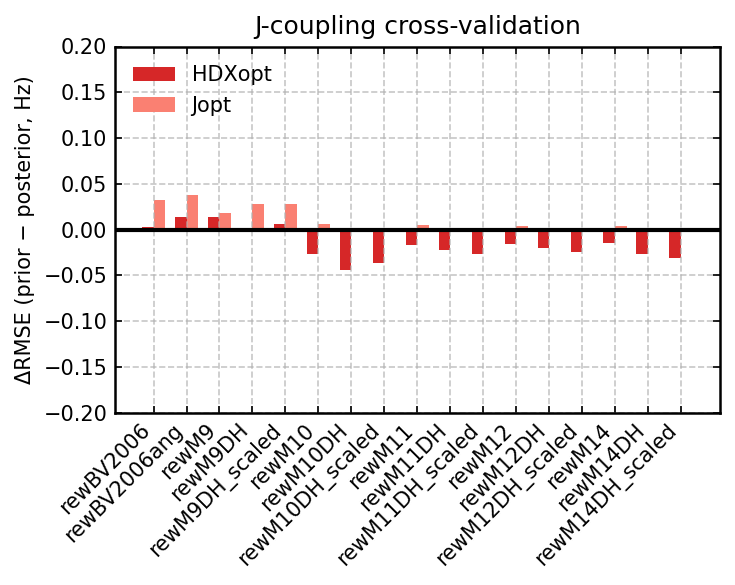

In [4]:
# summary barplot (delta Q-factor prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (Jopt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

proteins = ['aSyn', 'drkN']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_Jcoupling_validation.csv')

        prior.append(list(dat['J_RMSE'])[0])
        post1.append(list(dat['J_RMSE'])[-1])
        post2.append(np.min(dat['J_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['Jopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['Jopt'], width, label='Jopt ', color = 'salmon')

ax.set_ylabel('ΔRMSE (prior − posterior, Hz)')
ax.set_title('J-coupling cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.2,0.2)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'Jcoupling_validation_summary.png',dpi=300)





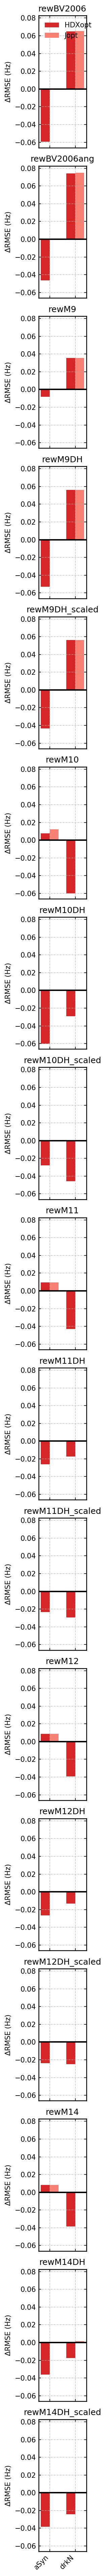

In [5]:
proteins = ['aSyn', 'drkN']

# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_Jcoupling_validation.csv')

        prior = list(dat['J_RMSE'])[0]
        post1 = list(dat['J_RMSE'])[-1]
        post2 = np.min(dat['J_RMSE'])

        delta_HDXopt = prior - post1
        delta_Jopt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "Jopt": delta_Jopt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(2, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "Jopt"]].min().min() * 1.1
ymax = df[["HDXopt", "Jopt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["Jopt"], width, label="Jopt", color="salmon")

    ax.axhline(0, color="black")
    ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔRMSE (Hz)")

    if idx == 0:
        ax.legend(loc="upper left")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + "Jcoupling_validation_per_protein_per_model.png", dpi=300)

